<a href="https://colab.research.google.com/github/annjgs/Cosmic-Rays-Simulator/blob/main/Muon_Box.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

week 1

In [4]:
import numpy as np
import matplotlib.pyplot as plt

# -----------------------------------------------------------------------------
# 1) Critical angle and analytical fraction (points 1, 3 and 4)
# -----------------------------------------------------------------------------
n = 1.58  # refractive index of EJ-200

theta_c = np.arcsin(1 / n)          # critical angle (rad)
cos_c = np.cos(theta_c)

f_one_face = (1 - cos_c) / 2        # point 2 and 3: fraction escaping through 1 face
f_escape_box = 6 * f_one_face       # point 4: 6 faces, non-overlapping cones
f_trapped_box = 1 - f_escape_box    # trapped fraction in the box (analytical)

print(f"theta_c            = {np.degrees(theta_c):.3f} degrees")
print(f"cos(theta_c)       = {cos_c:.5f}")
print(f"escape fraction (1 face)  = {f_one_face:.5f}")
print(f"escape fraction (box)     = {f_escape_box:.5f}")
print(f"trapped fraction (box)    = {f_trapped_box:.5f}  <-- control value from point 4")
print()



theta_c            = 39.265 degrees
cos(theta_c)       = 0.77422
escape fraction (1 face)  = 0.11289
escape fraction (box)     = 0.67733
trapped fraction (box)    = 0.32267  <-- control value from point 4



# 2) Monte Carlo simulation of the bare box

In [8]:
def simulate_escape_fraction(N, rng):
    """
    Generates N photons with isotropic direction and returns the fraction
    that escapes the box (no absorption, no reflector).

    Correct isotropic sampling: cos(theta) uniform in [-1, 1] and phi
    uniform in [0, 2*pi]. WARNING: theta uniform in [0, pi] is NOT
    isotropic (it oversamples the poles) — this is a classic mistake at
    this point.
    """
    costheta = rng.uniform(-1, 1, N)
    sintheta = np.sqrt(1 - costheta**2)
    phi = rng.uniform(0, 2 * np.pi, N)

    vx = sintheta * np.cos(phi)
    vy = sintheta * np.sin(phi)
    vz = costheta

    # A photon escapes if its angle with respect to ANY of the 3 normals
    # (x, y, z) falls inside that face's escape cone, i.e. if the
    # corresponding component exceeds cos(theta_c) in absolute value.
    escapes = (np.abs(vx) > cos_c) | (np.abs(vy) > cos_c) | (np.abs(vz) > cos_c)
    return np.mean(escapes)


Ns = [100, 1_000, 10_000, 100_000]
REPEATS = 30  # independent runs per N, used to estimate the error bar

rng = np.random.default_rng(42)  # fixed seed for reproducibility

mean_trapped = []
error_trapped = []

for N in Ns:
    runs = np.array([1 - simulate_escape_fraction(N, rng) for _ in range(REPEATS)])
    mean_value = runs.mean()
    standard_error = runs.std(ddof=1) / np.sqrt(REPEATS)

    mean_trapped.append(mean_value)
    error_trapped.append(standard_error)

    diff_pct = abs(mean_value - f_trapped_box) * 100
    status = " " if diff_pct < 1.0 else "CHECK (differs > 1%)"
    print(f"N={N:>7d}   trapped_fraction_MC = {mean_value:.5f} +- {standard_error:.5f}   "
          f"diff vs analytical = {diff_pct:.3f}%   {status}")

N=    100   trapped_fraction_MC = 0.31867 +- 0.00867   diff vs analytical = 0.401%    
N=   1000   trapped_fraction_MC = 0.32470 +- 0.00277   diff vs analytical = 0.203%    
N=  10000   trapped_fraction_MC = 0.32261 +- 0.00088   diff vs analytical = 0.006%    
N= 100000   trapped_fraction_MC = 0.32231 +- 0.00026   diff vs analytical = 0.036%    


# 3) Plot: trapped fraction vs N, with error bars

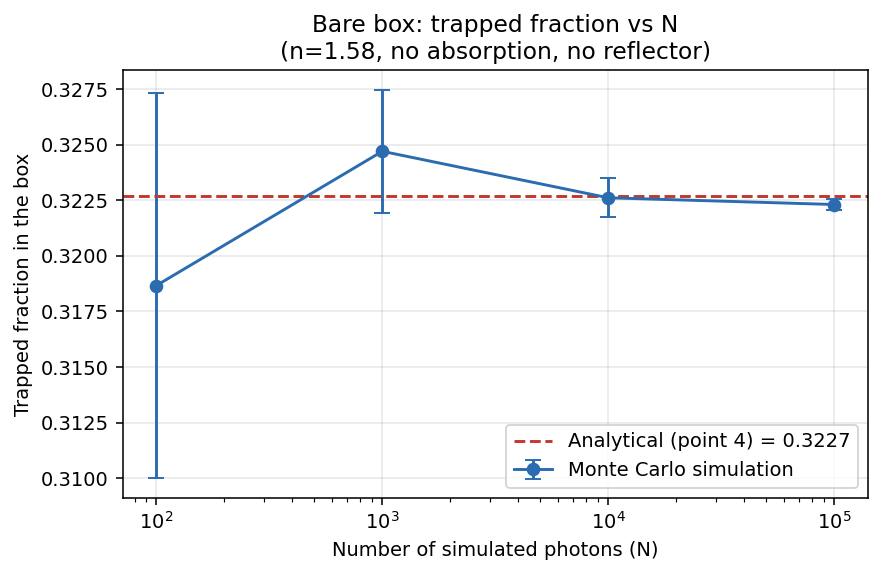

In [6]:
fig, ax = plt.subplots(figsize=(6.4, 4.2), dpi=140)

ax.errorbar(Ns, mean_trapped, yerr=error_trapped, fmt='o-',
            capsize=4, color='#2b6cb0', label='Monte Carlo simulation')
ax.axhline(f_trapped_box, color='#c0392b', linestyle='--',
           label=f'Analytical (point 4) = {f_trapped_box:.4f}')

ax.set_xscale('log')
ax.set_xlabel('Number of simulated photons (N)')
ax.set_ylabel('Trapped fraction in the box')
ax.set_title('Bare box: trapped fraction vs N\n(n=1.58, no absorption, no reflector)')
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()

# In Colab it's enough to let the figure display; to also save it:
fig.savefig('point6_trapped_fraction.png')
plt.show()